In [1]:
from auxin_signalling_models.ReducedAuxinSignallingPathway import \
    ReducedAuxinSignallingPathway as reduced_asp_class
from auxin_signalling_models.AuxinSignallingPathway import AuxinSignallingPathway as asp_class

import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import sympy as sp
import scipy

In [2]:
kwargs = {'nARFs': 1, 'nIAAs': 1}

asp_model_r = reduced_asp_class(**kwargs, include_arf_transcription=True)
asp_model_full = asp_class(**kwargs, include_arf_transcription=True)

In [3]:
# Find all parameters related to the promoter-protein dynamics
empty_set_node = asp_model_full.empty_set_node
aux_symbol = asp_model_full.auxin_variable_label

pp_reactions = []
promoter_symbols = [s.name for s in asp_model_full.get_state_variables() if s.category=="promoter"]

asp_model_full.remove_state_variable_by_name("G__ARF_1")

for r in asp_model_full._reactions_set:
    if np.all(np.isin(r.reactants + r.products, promoter_symbols)):
        pp_reactions.append(r)
    
pp_parameters = [s for r in pp_reactions for s in r.fwd_rates + r.bwd_rates]
print(asp_model_full.get_default_parameters())
print(pp_parameters)

{'d__D__ARF_1__ARF_1': 0.1, 'd__D__ARF_1__iaa_1': 0.1, 'd__D__iaa_1__iaa_1': 0.1, 'd__G__ARF_1': 1.0, 'd__G__ARF_1__ARF_1': 1.0, 'd__G__ARF_1__iaa_1': 1.0, 'd__R': 0.01, 'd__arf__all': 1.0, 'd__iaa_1__x': 0.1, 'd__iaa__all': 1.0, 'k__D__ARF_1__ARF_1': 0.001, 'k__D__ARF_1__iaa_1': 0.001, 'k__D__iaa_1__iaa_1': 0.001, 'k__G__ARF_1': 1.0, 'k__G__ARF_1__ARF_1': 1.0, 'k__G__ARF_1__ARF_1__R__ARF_1': 1.0, 'k__G__ARF_1__ARF_1__R__iaa_1': 1.0, 'k__G__ARF_1__R__ARF_1': 1.0, 'k__G__ARF_1__R__iaa_1': 1.0, 'k__G__ARF_1__iaa_1': 1.0, 'k__G__ARF_1__iaa_1__R__ARF_1': 1.0, 'k__G__ARF_1__iaa_1__R__iaa_1': 1.0, 'k__G__R__ARF_1': 1.0, 'k__G__R__iaa_1': 1.0, 'k__R__ARF_1__ARF_1': 1.0, 'k__R__iaa_1__iaa_1': 1.0}
['d__G__ARF_1__ARF_1', 'k__G__ARF_1__ARF_1', 'k__G__ARF_1__iaa_1', 'd__G__ARF_1__iaa_1']


In [4]:
promoter_timeconstant = 'tau_G'
asp_model_full.add_model_parameter(promoter_timeconstant, 1.0, "Promoter timeconstant", strict=False)
asp_model_full.add_model_parameter("k__RNA__IAA", 1.0, "", strict=False)

full_parameter_subs_dict = asp_model_r.parameter_subs_dict.copy()

for p in pp_parameters:
    if p in full_parameter_subs_dict:
        print(f"{full_parameter_subs_dict[p]}")
    else:
        full_parameter_subs_dict[p] = sp.sympify(p) / sp.sympify(promoter_timeconstant)

print(full_parameter_subs_dict)

tau_G
k__RNA__IAA
{'k__R__iaa_1__iaa_1': 'k__RNA__IAA', 'k__R__ARF_1__ARF_1': 'k__RNA__ARF', 'd__G__ARF_1__ARF_1': d__G__ARF_1__ARF_1/tau_G, 'k__G__ARF_1__ARF_1': k__G__ARF_1__ARF_1/tau_G, 'k__G__ARF_1__iaa_1': k__G__ARF_1__iaa_1/tau_G, 'd__G__ARF_1__iaa_1': d__G__ARF_1__iaa_1/tau_G}


Matrix([[-2*ARF_1**2*k__D__ARF_1__ARF_1 - ARF_1*d__arf__all - ARF_1*iaa_1*k__D__ARF_1__iaa_1 + 2*D__ARF_1__ARF_1*d__D__ARF_1__ARF_1 + D__ARF_1__iaa_1*d__D__ARF_1__iaa_1 + R__ARF_1*k__RNA__ARF], [ARF_1**2*k__D__ARF_1__ARF_1 - D__ARF_1__ARF_1*d__D__ARF_1__ARF_1], [ARF_1*iaa_1*k__D__ARF_1__iaa_1 - D__ARF_1__iaa_1*d__D__ARF_1__iaa_1], [-D__iaa_1__iaa_1*d__D__iaa_1__iaa_1 + iaa_1**2*k__D__iaa_1__iaa_1], [(-D__ARF_1__ARF_1*G*k__G__ARF_1__ARF_1 - D__ARF_1__iaa_1*G*k__G__ARF_1__iaa_1 + G__ARF_1__ARF_1*d__G__ARF_1__ARF_1 + G__ARF_1__iaa_1*d__G__ARF_1__iaa_1)/tau_G**2], [(D__ARF_1__ARF_1*G*k__G__ARF_1__ARF_1 - G__ARF_1__ARF_1*d__G__ARF_1__ARF_1)/tau_G**2], [(D__ARF_1__iaa_1*G*k__G__ARF_1__iaa_1 - G__ARF_1__iaa_1*d__G__ARF_1__iaa_1)/tau_G**2], [G*k__G__R__ARF_1 + G__ARF_1__ARF_1*k__G__ARF_1__ARF_1__R__ARF_1 + G__ARF_1__iaa_1*k__G__ARF_1__iaa_1__R__ARF_1 - R__ARF_1*d__R], [G*k__G__R__iaa_1 + G__ARF_1__ARF_1*k__G__ARF_1__ARF_1__R__iaa_1 + G__ARF_1__iaa_1*k__G__ARF_1__iaa_1__R__iaa_1 - R__iaa_1*d__R

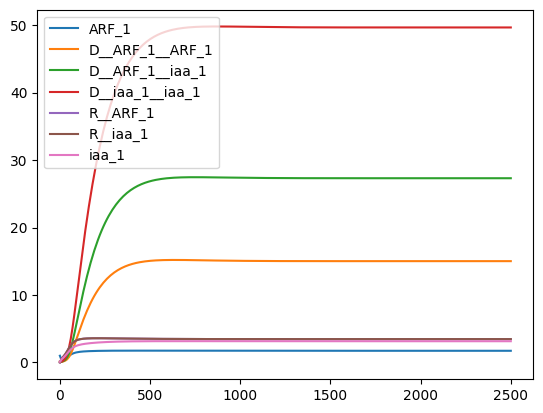

In [5]:
reduced_solver = asp_model_r.make_forward_solver()
reduced_ic_dict = asp_model_r.get_default_initial_conditions()
reduced_param_dict =  asp_model_r.get_default_parameters()

new_param_dict = {
    'd__D__ARF_1__ARF_1': 0.01,
    'd__D__ARF_1__iaa_1': 0.01,
    'd__D__iaa_1__iaa_1': 0.01,
    'd__G__ARF_1__ARF_1': 1.0,
    'd__G__ARF_1__iaa_1': 1.0, 
    'd__R': 0.1, 
    'd__arf__all': 2.0, 
    'd__iaa_1__x': 1.0, 
    'd__iaa__all': 0.1,
    'k__D__ARF_1__ARF_1': 0.05,
    'k__D__ARF_1__iaa_1': 0.05,
    'k__D__iaa_1__iaa_1': 0.05,
    'k__G__ARF_1__ARF_1': 1.0, 
    'k__G__ARF_1__ARF_1__R__iaa_1': 1.0,
    'k__G__ARF_1__iaa_1__R__iaa_1': 0.0, 
    'k__G__R__iaa_1': 0.001, 
    'k__G__ARF_1__ARF_1__R__ARF_1': 1.0,
    'k__G__ARF_1__iaa_1__R__ARF_1': 0.0, 
    'k__G__R__ARF_1': 0.0001, 
    'k__G__ARF_1__iaa_1': 1.0, 
    'k__RNA__IAA': 1.0, 
    'k__arf__all': 1.0, 
    'tau_G': 1.0
}

for lab in reduced_param_dict:
    if lab in new_param_dict:
        reduced_param_dict[lab] = new_param_dict[lab]

ts = np.linspace(0, 2500, 250)

sol1, succ = reduced_solver(ts, reduced_param_dict, reduced_ic_dict, 1.0)
r_odes, free_variables, parameters, constraints = asp_model_r.generate_ode_system()
f_odes, free_variables, parameters, constraints = asp_model_full.generate_ode_system(parameter_subs_dict=full_parameter_subs_dict)

plt.plot(ts, sol1, label=reduced_ic_dict.keys())
plt.legend()

print(sp.simplify(f_odes))

['d__D__ARF_1__ARF_1', 'd__D__ARF_1__iaa_1', 'd__D__iaa_1__iaa_1', 'd__G__ARF_1', 'd__G__ARF_1__ARF_1', 'd__G__ARF_1__iaa_1', 'd__R', 'd__arf__all', 'd__iaa_1__x', 'd__iaa__all', 'k__D__ARF_1__ARF_1', 'k__D__ARF_1__iaa_1', 'k__D__iaa_1__iaa_1', 'k__G__ARF_1', 'k__G__ARF_1__ARF_1', 'k__G__ARF_1__ARF_1__R__ARF_1', 'k__G__ARF_1__ARF_1__R__iaa_1', 'k__G__ARF_1__R__ARF_1', 'k__G__ARF_1__R__iaa_1', 'k__G__ARF_1__iaa_1', 'k__G__ARF_1__iaa_1__R__ARF_1', 'k__G__ARF_1__iaa_1__R__iaa_1', 'k__G__R__ARF_1', 'k__G__R__iaa_1', 'k__RNA__ARF', 'k__RNA__IAA', 'tau_G']
{'d__D__ARF_1__ARF_1': 0.1, 'd__D__ARF_1__iaa_1': 0.1, 'd__D__iaa_1__iaa_1': 0.1, 'd__G__ARF_1': 1.0, 'd__G__ARF_1__ARF_1': 1.0, 'd__G__ARF_1__iaa_1': 1.0, 'd__R': 0.01, 'd__arf__all': 1.0, 'd__iaa_1__x': 0.1, 'd__iaa__all': 1.0, 'k__D__ARF_1__ARF_1': 0.001, 'k__D__ARF_1__iaa_1': 0.001, 'k__D__iaa_1__iaa_1': 0.001, 'k__G__ARF_1': 1.0, 'k__G__ARF_1__ARF_1': 1.0, 'k__G__ARF_1__ARF_1__R__ARF_1': 1.0, 'k__G__ARF_1__ARF_1__R__iaa_1': 1.0, 'k__G

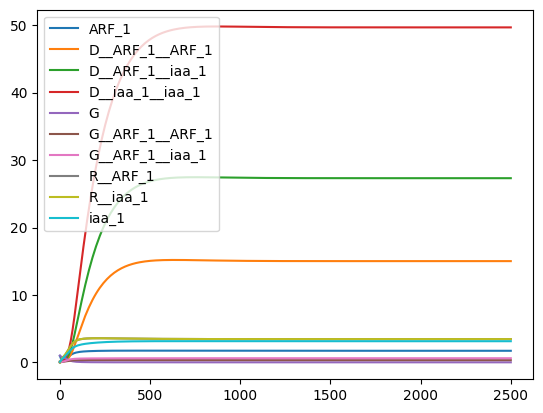

In [6]:
full_param_dict = asp_model_full.get_default_parameters(parameter_subs_dict=full_parameter_subs_dict)

for k, v in reduced_param_dict.items():
    if k in full_param_dict:
        full_param_dict[k] = v

full_ic_dict = asp_model_full.get_default_initial_conditions()

for k, v in reduced_param_dict.items():
    full_param_dict[k] = v

full_param_dict[promoter_timeconstant] = 1.0

print(list(full_param_dict.keys()))
print(asp_model_full.get_default_parameters())

full_solver = asp_model_full.make_forward_solver(parameter_subs_dict=full_parameter_subs_dict,
                                                rtol=1e-5, atol=1e-5)
sol2, succ = full_solver(ts, full_param_dict, full_ic_dict, 1, strict=False)

print(full_ic_dict)
plt.plot(ts, sol2, label=full_ic_dict.keys())
plt.legend()

odes, free_variables, parameters, \
            _ = asp_model_r.generate_ode_system(
                                         reduced=True)

['ARF_1', 'D__ARF_1__ARF_1', 'D__ARF_1__iaa_1', 'D__iaa_1__iaa_1', 'R__ARF_1', 'R__iaa_1', 'iaa_1']
['ARF_1', 'D__ARF_1__ARF_1', 'D__ARF_1__iaa_1', 'D__iaa_1__iaa_1', 'G', 'G__ARF_1__ARF_1', 'G__ARF_1__iaa_1', 'R__ARF_1', 'R__iaa_1', 'iaa_1']
starting solve
0.0012897515723022774
[[1.         0.1        0.1        0.1        1.         0.
  0.         0.         0.         0.1       ]
 [0.27401427 0.11626638 0.11684299 0.13287431 0.81137745 0.09418794
  0.09443461 0.57659669 0.58129263 0.47598907]
 [0.42559392 0.16584931 0.21135356 0.30417736 0.72691328 0.12020512
  0.15288161 0.89397837 0.90007253 0.73956812]
 [0.58362758 0.2719756  0.40182146 0.63895938 0.59828879 0.16224816
  0.23946305 1.23855949 1.24452469 1.00261047]
 [0.7742773  0.46716856 0.74062581 1.22118745 0.45358098 0.21141016
  0.33500885 1.66272367 1.66784023 1.31275907]]
starting solve
0.0018848301151875174
[[1.         0.1        0.1        0.1        1.         0.
  0.         0.         0.         0.1       ]
 [0.2732

0.24217561202718257
[[1.         0.1        0.1        0.1        1.         0.
  0.         0.         0.         0.1       ]
 [0.06754441 0.1019648  0.0928225  0.09227861 0.93198013 0.03563914
  0.03238072 0.14341536 0.14887228 0.11912795]
 [0.17165108 0.0996981  0.09726033 0.10714942 0.89435086 0.05489397
  0.05075517 0.35545295 0.3626338  0.30610634]
 [0.25591232 0.11280213 0.1282809  0.1687288  0.8647488  0.06803675
  0.06721446 0.5280765  0.53571016 0.45528098]
 [0.32625472 0.14297495 0.1886832  0.28152866 0.82766638 0.08192229
  0.09041133 0.67472967 0.68234069 0.57746991]]
starting solve
0.3198159329426131
[[1.         0.1        0.1        0.1        1.         0.
  0.         0.         0.         0.1       ]
 [0.04993375 0.10172109 0.09240807 0.09157267 0.94911411 0.02666588
  0.02422001 0.10528433 0.11080681 0.08931431]
 [0.13262436 0.09632635 0.09134952 0.09678875 0.91682279 0.04340047
  0.03977674 0.27369359 0.28101575 0.23850606]
 [0.20453842 0.10121859 0.10792788 0.1329

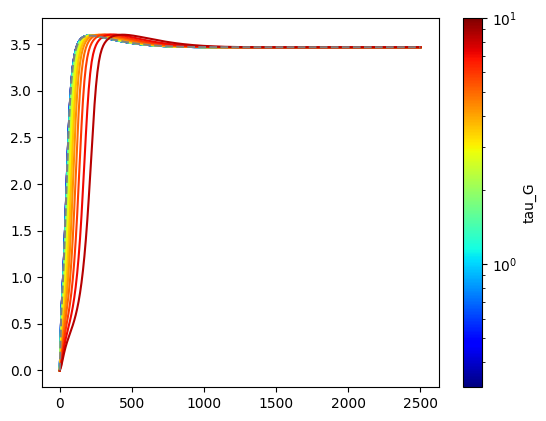

In [12]:
plt.clf()

cmap = plt.get_cmap('jet') 

rmses = []
tau_vals = 10**np.linspace(-0.5, 1, 20)

parameter_subs_dict = asp_model_r.parameter_subs_dict

for k, v in reduced_param_dict.items():
    full_param_dict[k] = v
    
for k,v in full_param_dict.items():
    if k not in reduced_param_dict.keys():
        full_param_dict[k] = 0.0

plot_var_index = -2

print(sorted(reduced_ic_dict.keys()))
print(sorted(full_ic_dict.keys()))

sol1, succ = reduced_solver(ts, reduced_param_dict, reduced_ic_dict, 1.0)

parameter_subs_dict = asp_model_r.parameter_subs_dict
for i, tau in enumerate(tau_vals):
    print("starting solve")
    # full_param_dict = asp_model_full.get_default_parameters(parameter_subs_dict=parameter_subs_dict)
    full_param_dict[promoter_timeconstant] = tau
    sol2, succ = full_solver(ts, full_param_dict, full_ic_dict, 1.0)
    color = cmap(i / len(tau_vals)) 
    plt.plot(ts, sol2[:, plot_var_index], color=color)
    
    rmse = np.sqrt(np.mean((sol2[1:, plot_var_index] - sol1[1:, plot_var_index])**2))
    rmses.append(rmse)
    print(rmse)
    print(sol2[0:5, :])

plt.colorbar(mpl.cm.ScalarMappable(norm=mpl.colors.LogNorm(tau_vals[0], tau_vals[-1]), cmap='jet'),
             orientation='vertical', label='tau_G', ax=plt.gca())
plt.plot(ts, sol1[:, plot_var_index], color='grey', ls='--')


In [8]:
steps_taken_list = []
x0 = np.array(list(full_ic_dict.values()))
p = np.array(list(full_param_dict.values()))

_ts = [ts[0], ts[-1]]
parameter_subs_dict = full_parameter_subs_dict

_rhs_func = asp_model_full.generate_rhs_func(parameter_subs_dict=parameter_subs_dict)

def wrapped_rhs_func(t, y, p, aux):
    return _rhs_func(y, t, p, aux).flatten()

jac_func = asp_model_full.generate_jacobian_func(parameter_subs_dict=parameter_subs_dict)
def wrapped_jac_func(t, y, p, aux):
    return jac_func(y, t, p, aux)

for i, tau in enumerate(tau_vals):
    print(tau)
    full_param_dict[promoter_timeconstant] = tau
    p = np.array(list([full_param_dict[k] for k in sorted(full_param_dict.keys())]))
    res = scipy.integrate.solve_ivp(wrapped_rhs_func, t_span=_ts, y0=x0, args=[p, [1.0]],
                                    method="LSODA", jac=wrapped_jac_func)
    steps_taken = res.nfev
    steps_taken_list.append(steps_taken)
print(steps_taken_list)



0.31622776601683794
13.33521432163324
562.341325190349
23713.737056616552
1000000.0
[1639615, 1351, 190, 193, 189]


/home/pmzjs/code/auxin_signalling_models/.venv/lib/python3.12/site-packages/scipy/integrate/_ivp/ivp.py:623: UserWarning: The following arguments have no effect for a chosen solver: `full_output`.
  solver = method(fun, t0, y0, tf, vectorized=vectorized, **options)


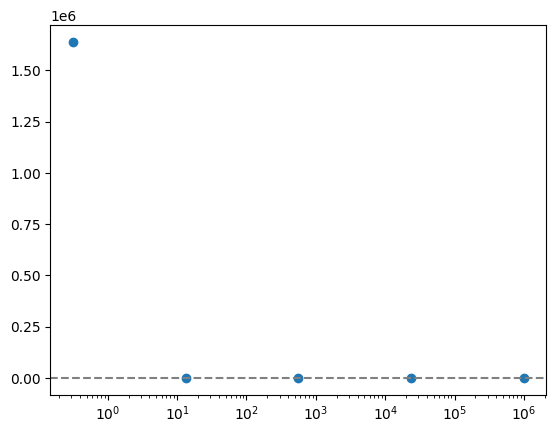

In [9]:
# Now the reduced model
x0 = np.array(list(reduced_ic_dict.values()))
p = np.array(list(reduced_param_dict.values()))

_rhs_func = asp_model_r.generate_rhs_func()

def wrapped_rhs_func(t, y, p, aux):
    return _rhs_func(y, t, p, aux).flatten()


jac_func = asp_model_full.generate_jacobian_func(parameter_subs_dict=parameter_subs_dict)
def wrapped_jac_func(t, y, p, aux):
    return jac_func(y, t, p, aux)

res = scipy.integrate.solve_ivp(wrapped_rhs_func, t_span = [0, 1], y0=x0, args=(p, [1.0]),
                                    full_output=True, method="LSODA")
y = res.y

steps_taken = res.nfev

plt.scatter(tau_vals, steps_taken_list)

ax = plt.gca()
ax.axhline(steps_taken, ls='--', color='grey')
ax.set_xscale('log')

Text(0.5, 0, 'tau_G')

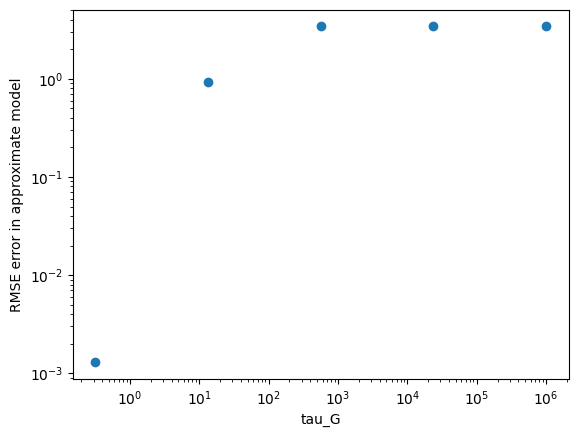

In [10]:
plt.scatter(tau_vals, rmses)
plt.xscale('log')
plt.yscale('log')
plt.ylabel("RMSE error in approximate model")
plt.xlabel("tau_G")